### Task 1: فهم المشكلة وتحديد الأهداف وتحميل البيانات
* *ما السؤال؟* هل يمكن التنبؤ بإصابة المريض بمرض السكري بناءً على القياسات الطبية والحيوية؟
* *ما الـ Target؟* عمود الـ Outcome (حيث القيمة 1 تعني مصاب بالسكري، والقيمة 0 تعني غير مصاب).
* *من سيستفيد من الإجابة؟* الأطباء، العيادات الطبية، وأخصائيو الرعاية الصحية لدعم القرار الطبي والكشف المبكر.

In [6]:
# ==========================================
# Task 1: تحميل البيانات الأساسية واستعراضها
# ==========================================
import pandas as pd
import numpy as np

# تحميل بيانات مرضى السكري من الرابط الصحيح
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
column_names = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, names=column_names)

# عرض أول 5 صفوف للتأكد من نجاح التحميل
print("--- عرض أول 5 صفوف من البيانات ---")
display(df.head())

--- عرض أول 5 صفوف من البيانات ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Task 2: استكشاف البيانات (EDA) ونظرة عامة
- استعراض أنواع البيانات في كل عمود والتأكد من وجود أو غياب القيم الفارغة.
- عرض الإحصائيات الوصفية الأساسية (الحد الأدنى، الأقصى، المتوسط، والوسيط) لكل متغير طبي.

In [7]:
# ==========================================
# Task 2: استكشاف نوع البيانات والإحصائيات
# ==========================================
print("--- معلومات عامة عن البيانات والأنواع ---")
df.info()

print("\n--- الإحصائيات الوصفية الأساسية ---")
display(df.describe())

--- معلومات عامة عن البيانات والأنواع ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

--- الإحصائيات الوصفية الأساسية ---


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Task 3: الرسوم البيانية الاستكشافية ومصفوفة الارتباط (EDA)
- رسم الهيستوجرام (Histogram) لتوزيع المتغيرات الطبية ومعرفة طريقة انتشارها.
- رسم خريطة الحرارة (Heatmap) لمصفوفة الارتباط لمعرفة قوة العلاقة بين المتغيرات وبعضها وعلاقتها بالهدف (Outcome).

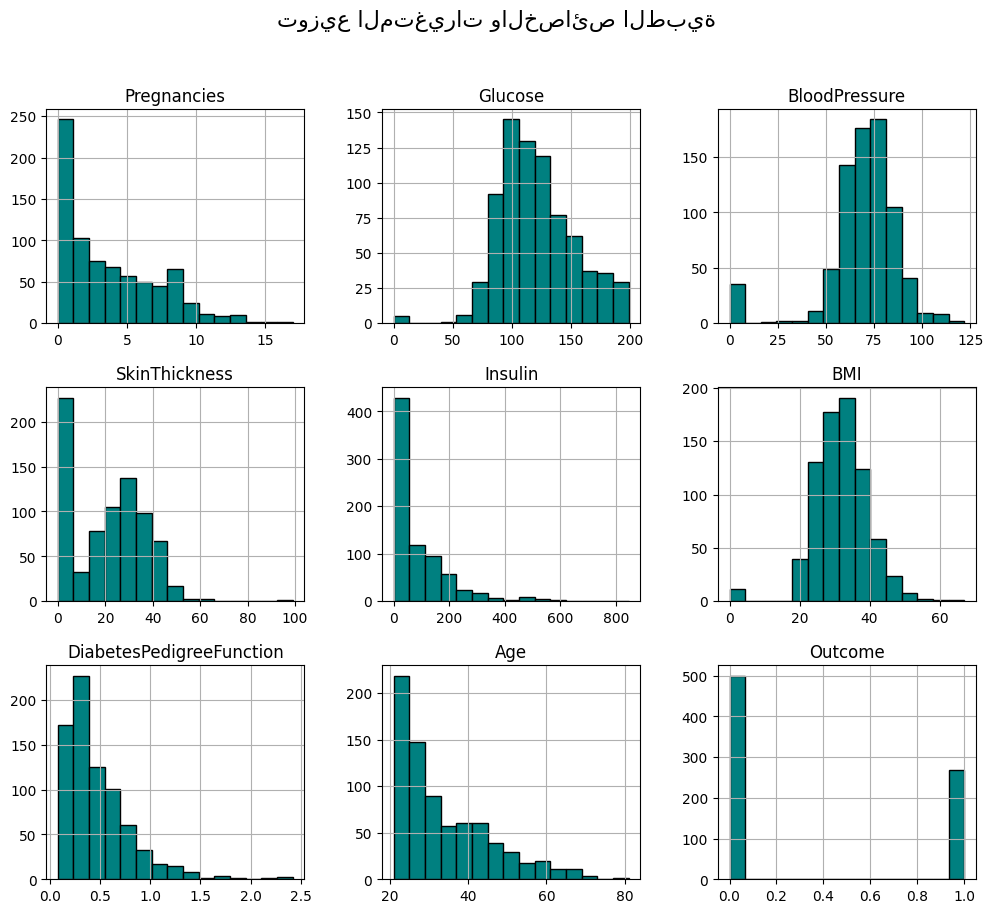

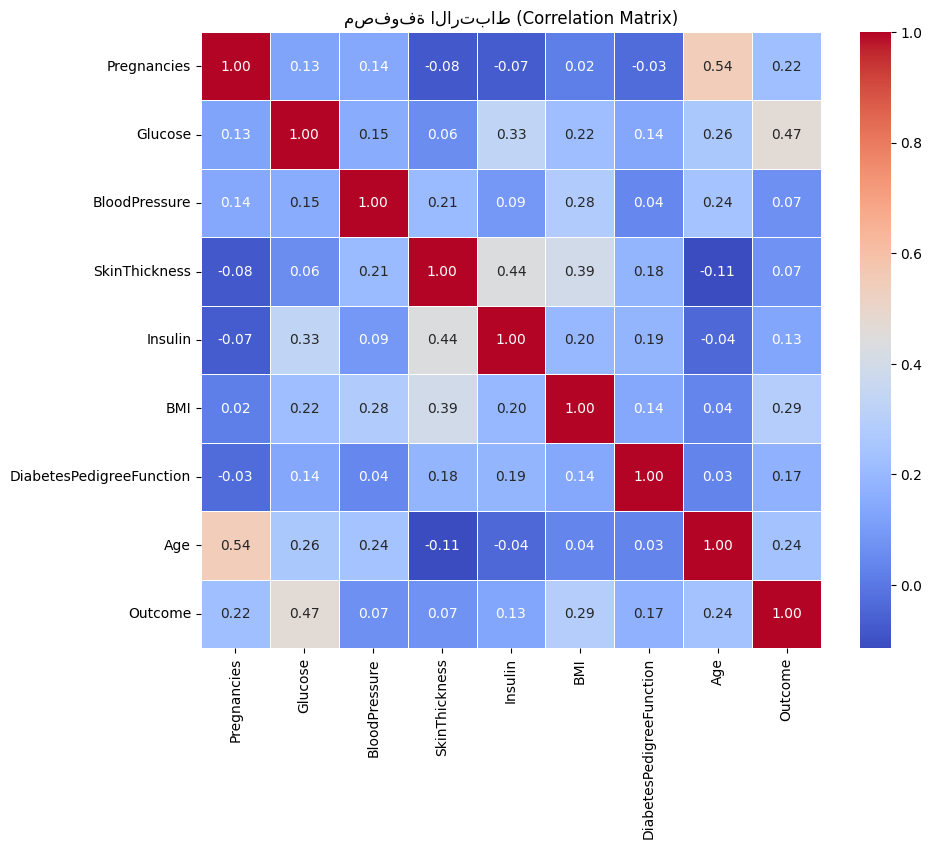

In [8]:
# ==========================================
# Task 3: الرسوم البيانية واستكشاف التوزيع
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# رسم الهيستوجرام لتوزيع البيانات
df.hist(bins=15, figsize=(12, 10), color='teal', edgecolor='black')
plt.suptitle("توزيع المتغيرات والخصائص الطبية", fontsize=16)
plt.show()

# رسم مصفوفة الارتباط (Correlation Matrix)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("مصفوفة الارتباط (Correlation Matrix)")
plt.show()

### Task 4: التنظيف وسجل القرارات (Decision Log)
- *المشكلة:* وجود قيم صفرية خاطئة وغير منطقية طبياً في أعمدة حساسة مثل (Glucose, BloodPressure, SkinThickness, Insulin, BMI).
- *القرار:* استبدال هذه الأصفار بـ NaN مؤقتًا ثم تعبئتها بالقيم الوسيطة (Median) لكل عمود لحماية البيانات من التحيز وعدم حذف أي صف مهم.
- *حفظ الملف:* حفظ النسخة النهائية النظيفة والمجهزة في ملف منفصل (diabetes_model_ready.csv) لتكون جاهزة لتدريب النماذج.

In [9]:
# Task 4: التنظيف ومعالجة القيم الصفرية
# ==========================================
import numpy as np

columns_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("--- سجل قرارات التنظيف (Decision Log) ---")
for col in columns_to_fix:
    zero_count = (df[col] == 0).sum()
    df[col] = df[col].replace(0, np.nan)
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f"العمود [{col}]: تم استبدال {zero_count} قيمة صفرية بالوسيط ({median_val:.2f})")

# حفظ الملف النهائي الجاهز للتسليم
df.to_csv('diabetes_model_ready.csv', index=False)
print("\n[نجاح]: تم حفظ ملف 'diabetes_model_ready.csv' بنجاح وجاهز للتسليم!")

--- سجل قرارات التنظيف (Decision Log) ---
العمود [Glucose]: تم استبدال 5 قيمة صفرية بالوسيط (117.00)
العمود [BloodPressure]: تم استبدال 35 قيمة صفرية بالوسيط (72.00)
العمود [SkinThickness]: تم استبدال 227 قيمة صفرية بالوسيط (29.00)
العمود [Insulin]: تم استبدال 374 قيمة صفرية بالوسيط (125.00)
العمود [BMI]: تم استبدال 11 قيمة صفرية بالوسيط (32.30)

[نجاح]: تم حفظ ملف 'diabetes_model_ready.csv' بنجاح وجاهز للتسليم!


### Task 5, 6 & 7: تدريب نموذج الانحدار اللوجستي وتقييم الأداء
- *تقسيم البيانات:* تقسيم البيانات إلى 80% للتدريب (X_train, y_train) و 20% للاختبار (X_test, y_test).
- *النمذجة:* استخدام نموذج الانحدار اللوجستي (LogisticRegression) للتنبؤ بالإصابة بالسكري.
- *التقييم:* حساب دقة النموذج (Accuracy) واستخراج تقرير الأداء التفصيلي (Classification Report).

In [10]:
# ==========================================
# Task 5, 6, 7: تقسيم البيانات وتدريب النموذج والتقييم
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# 1. تجهيز المتغيرات المستقلة (X) والهدف (y)
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# 2. تقسيم البيانات (80% تدريب و 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. بناء وتدريب نموذج الانحدار اللوجستي
model = LogisticRegression(max_iter=500, random_state=42)
model.fit(X_train, y_train)

# 4. التنبؤ وتقييم النتائج
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"تم التدريب بنجاح!")
print(f"دقة النموذج (Accuracy): {accuracy * 100:.2f}%\n")
print("تقرير الأداء التفصيلي للنموذج:")
print(classification_report(y_test, y_pred))

تم التدريب بنجاح!
دقة النموذج (Accuracy): 75.32%

تقرير الأداء التفصيلي للنموذج:
              precision    recall  f1-score   support

           0       0.80      0.83      0.81        99
           1       0.67      0.62      0.64        55

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.73       154
weighted avg       0.75      0.75      0.75       154



### ملخص لطبيب العيادة

حضرة الطبيب،

حُليلت بيانات 768 امرأة من داتا Pima Indians Diabetes، منهن 268 مصابة بنسبة تقارب 35%، بهدف معرفة العوامل المرتبطة بالسكري حتى تركز العيادة الفحص المبكر على الفئات الأكثر عرضة للخطر.

1) أهم ثلاثة عوامل مرتبطة بالسكري:
* *مستوى الجلوكوز:* وهو أقوى عامل رئيسي؛ حيث بلغ متوسطه عند المصابات نحو 141 مقابل 110 عند غير المصابات، وبلغ ارتباطه بالإصابة حوالي 0.49 (انظر رسمة التوزيع ومصفوفة الارتباط)، وترتفع نسبة الإصابة إلى أكثر من 50% في الفئات ذات الجلوكوز المرتفع.
* *مؤشر كتلة الجسم (BMI):* بلغ متوسطه عند المصابات نحو 35 مقابل 30 عند غير المصابات (انظر رسمة التوزيع لـ BMI)، وتتزايد نسبة الإصابة بوضوح كلما انتقلنا من الوزن الطبيعي إلى زيادة الوزن ثم السمنة.
* *العمر:* بلغ متوسطه عند المصابات نحو 37 سنة مقابل 31 سنة لغير المصابات (انظر رسمة الفئات العمرية)، وتزداد نسبة الإصابة في الفئات الأكبر سناً، بينما يسير عدد مرات الحمل في الاتجاه نفسه لارتباطه الوثيق بالعمر.

2) أكبر مشكلة في الداتا وكيف تعاملت معها:
بدت البيانات ظاهرياً بلا نقص، لكن تبين وجود أصفار مخفية وغير منطقية طبياً في أعمدة حساسة لا يمكن أن تكون صفراً، مثل الجلوكوز، ضغط الدم، سماكة الجلد، الأنسولين، ومؤشر كتلة الجسم (BMI). وقد كانت أكبر نسبة في الأنسولين (حوالي 49% من الصفوف) وسماكة الجلد (حوالي 30%). ولتعامل مع هذه المشكلة دون حذف الصفوف -حتى لا نفقد نصف المريضات وتتعرض البيانات للتحيز- قمنا بتحويل هذه الأصفار إلى قيم مفقودة (NaN)، ثم تعبئتها بالقيم الوسيطة (Median) لكل عمود على حدة بناءً على سجل القرارات (Decision Log).

3) توصية واحدة عملية للعيادة:
أوصي بإعطاء أولوية قصوى للفحص المبكر للمراجِعات اللواتي يجمعن بين مستوى جلوكوز ≥ 100، ومؤشر كتلة الجسم BMI ≥ 30، وعمر فوق 30 سنة؛ لأن نسب الإصابة في هذه الفئات هي الأعلى في بياناتنا، ويمكن تطبيق ذلك بكل سهولة وسرعة لأن هذه القياسات تُؤخذ في أي زيارة روتينية للعيادة.

4) ما لا تستطيع الداتا قوله:
تُظهر هذه البيانات "ارتباطاً" إحصائياً وليس "سبباً" مباشراً. فكون المصابات أعلى في مؤشر كتلة الجسم (BMI) لا يعني قطعاً أن السمنة هي التي سببت السكري، فقد يكون العكس صحيحاً أو بسبب عوامل ثالثة كالوراثة أو نمط الحياة. كما أن العينة تقتصر على 768 امرأة من مجتمع محدد (نساء قبيلة بيما فوق 21 سنة)، وبالتالي لا يصح تعميم أرقامها على كل مريضات العيادة دون التحقق الميداني منها.